# Worked exercises — Qiskit fundamentals

Local, executable answers to the exercises in weeks 2–7 of
[JoeyRogers-svg/Qiskit-fundamentals](https://github.com/JoeyRogers-svg/Qiskit-fundamentals).
Added with AI assistance; the original course notebooks are kept unchanged.
Run from top to bottom. Assertions check the results against analytic answers.
All simulations are ideal and local; no IBM account or hardware jobs are used.

Qiskit labels a two-qubit state as **|q1 q0>**: qubit 0 is the rightmost bit.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp, concurrence
from qiskit.visualization import plot_bloch_multivector, plot_histogram

SEED = 42
def state(qc):
    return Statevector.from_instruction(qc)

def counts(qc, shots=4096):
    measured = qc.copy()
    measured.measure_all()
    return StatevectorSampler(seed=SEED).run([measured], shots=shots).result()[0].data.meas.get_counts()

## Week 2 — Single-qubit gates

Source: `week_2/1-single-qubit-gates-and-visualisation.ipynb`.
The table below explores all six initial states and ten gates using Bloch coordinates.
Z leaves |0> unchanged and gives |1> a global minus sign, so neither Bloch vector
changes. On a superposition, Z changes the relative phase.
S is a quarter turn around Z: S² = Z, and S† undoes S.
H² = I for every input state; HZH = X.

In [2]:
paulis = [SparsePauliOp(p) for p in ['X', 'Y', 'Z']]
for label in ['0', '1', '+', '-', 'r', 'l']:
    initial = Statevector.from_label(label)
    print('Initial:', label)
    for gate in ['x', 'y', 'z', 'h', 's', 'sdg', 't', 'tdg', 'sx', 'sxdg']:
        qc = QuantumCircuit(1)
        getattr(qc, gate)(0)
        final = initial.evolve(qc)
        bloch = [round(float(final.expectation_value(p).real), 3) for p in paulis]
        print(f'  {gate:4s}: {bloch}')

h = QuantumCircuit(1); h.h(0)
s = QuantumCircuit(1); s.s(0)
z = QuantumCircuit(1); z.z(0)
x = QuantumCircuit(1); x.x(0)
assert np.allclose(Operator(h).data @ Operator(h).data, np.eye(2))
assert np.allclose(Operator(s).data @ Operator(s).data, Operator(z).data)
assert np.allclose(Operator(s).data.conj().T @ Operator(s).data, np.eye(2))
assert np.allclose(Operator(h).data @ Operator(z).data @ Operator(h).data, Operator(x).data)

Initial: 0
  x   : [0.0, 0.0, -1.0]
  y   : [0.0, 0.0, -1.0]
  z   : [0.0, 0.0, 1.0]
  h   : [1.0, 0.0, 0.0]
  s   : [0.0, 0.0, 1.0]
  sdg : [0.0, 0.0, 1.0]
  t   : [0.0, 0.0, 1.0]
  tdg : [0.0, 0.0, 1.0]
  sx  : [0.0, -1.0, 0.0]
  sxdg: [0.0, 1.0, 0.0]
Initial: 1
  x   : [0.0, 0.0, 1.0]
  y   : [0.0, 0.0, 1.0]
  z   : [0.0, 0.0, -1.0]
  h   : [-1.0, 0.0, 0.0]
  s   : [0.0, 0.0, -1.0]
  sdg : [0.0, 0.0, -1.0]
  t   : [0.0, 0.0, -1.0]
  tdg : [0.0, 0.0, -1.0]
  sx  : [0.0, 1.0, 0.0]
  sxdg: [0.0, -1.0, 0.0]
Initial: +
  x   : [1.0, 0.0, 0.0]
  y   : [-1.0, 0.0, 0.0]
  z   : [-1.0, 0.0, 0.0]
  h   : [0.0, 0.0, 1.0]
  s   : [0.0, 1.0, 0.0]
  sdg : [0.0, -1.0, 0.0]
  t   : [0.707, 0.707, 0.0]
  tdg : [0.707, -0.707, 0.0]
  sx  : [1.0, 0.0, 0.0]
  sxdg: [1.0, 0.0, 0.0]
Initial: -
  x   : [-1.0, 0.0, 0.0]
  y   : [1.0, 0.0, 0.0]
  z   : [1.0, 0.0, 0.0]
  h   : [0.0, 0.0, -1.0]
  s   : [0.0, -1.0, 0.0]
  sdg : [0.0, 1.0, 0.0]
  t   : [-0.707, -0.707, 0.0]
  tdg : [-0.707, 0.707, 0.0]
  sx  : 

### Measurement and shot count

After H|0>, both outcomes have probability 1/2. Finite samples fluctuate;
the typical error decreases as 1/√shots, but not monotonically in every run.
Removing H makes every ideal measurement return 0. A fixed seed makes this
example repeatable; changing the seed gives a different sample.

20 {'1': 12, '0': 8}
200 {'1': 96, '0': 104}
20000 {'1': 10062, '0': 9938}


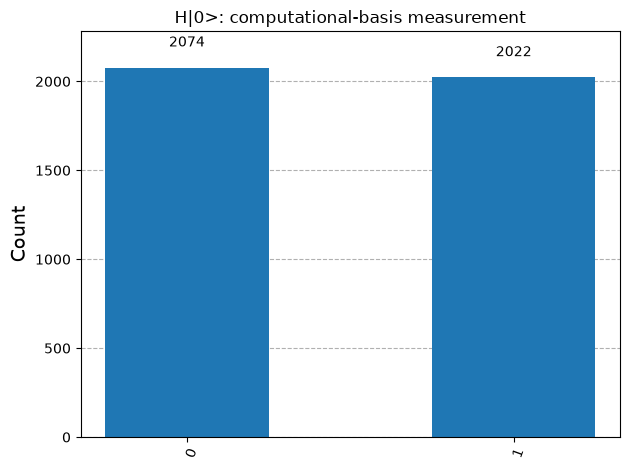

In [3]:
for shots in [20, 200, 20000]:
    observed = counts(h, shots)
    print(shots, observed)
    assert sum(observed.values()) == shots
assert counts(QuantumCircuit(1), 200) == {'0': 200}
assert np.allclose(state(h).probabilities(), [0.5, 0.5])
display(plot_histogram(counts(h), title='H|0>: computational-basis measurement'))
plt.close('all')

## Week 3 — All four Bell states

Source: `week_3/2-multiple-qubits.ipynb`.
H(0), CX(0,1) prepares Φ+. Applying Z(0) changes the relative sign;
X(1) changes the correlated pair 00/11 into the anticorrelated pair 01/10.
Each state has concurrence 1. Measurement in the computational basis alone
cannot distinguish the plus and minus versions.

In [4]:
bells = {}
expected = {
    'Phi+': [1, 0, 0, 1], 'Phi-': [1, 0, 0, -1],
    'Psi+': [0, 1, 1, 0], 'Psi-': [0, 1, -1, 0],
}
for name in expected:
    qc = QuantumCircuit(2)
    qc.h(0); qc.cx(0, 1)
    if name.startswith('Psi'): qc.x(1)
    if name.endswith('-'): qc.z(0)
    bells[name] = qc
    assert state(qc).equiv(np.array(expected[name]) / np.sqrt(2))
    assert np.isclose(concurrence(state(qc)), 1)
    print(name, np.round(state(qc).data, 3))

Phi+ [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
Phi- [ 0.707+0.j  0.   +0.j  0.   +0.j -0.707+0.j]
Psi+ [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]
Psi- [ 0.   +0.j -0.707+0.j  0.707+0.j  0.   +0.j]


## Week 4 — Exercise 1: Gate order

Source: `week_4/exercises.ipynb`.
H then S takes |0> to (|0> + i|1>)/√2, pointing along +Y.
S then H takes |0> to |+>, pointing along +X: these gates do not commute.
S and Z are a commuting example because both are diagonal.

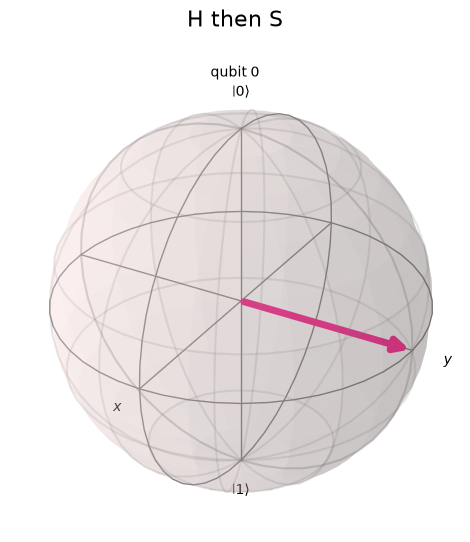

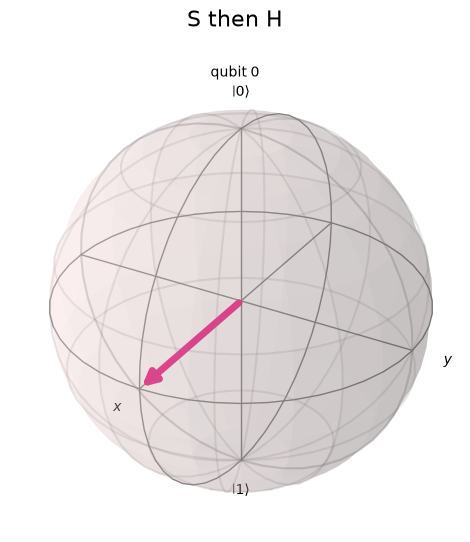

In [5]:
hs = QuantumCircuit(1); hs.h(0); hs.s(0)
sh = QuantumCircuit(1); sh.s(0); sh.h(0)
assert state(hs).equiv(Statevector.from_label('r'))
assert state(sh).equiv(Statevector.from_label('+'))
assert not state(hs).equiv(state(sh))
assert np.allclose(Operator(s).data @ Operator(z).data, Operator(z).data @ Operator(s).data)
display(plot_bloch_multivector(state(hs), title='H then S'))
display(plot_bloch_multivector(state(sh), title='S then H'))
plt.close('all')

### Exercise 2: Phase kickback

X|−> = −|−>. Therefore the controlled X adds a minus sign to the control's
|1> branch. The control changes from |+> to |−>, while the target stays |−>.
The final state remains a product state; CX does not always create entanglement.

In [6]:
kickback = QuantumCircuit(2)
kickback.h(0); kickback.x(1); kickback.h(1)
before = state(kickback)
kickback.cx(0, 1)
after = state(kickback)
assert before.equiv(Statevector.from_label('-+'))
assert after.equiv(Statevector.from_label('--'))
assert np.isclose(concurrence(after), 0, atol=1e-7)
print('Before:', before.data, '\nAfter:', after.data)

Before: [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j] 
After: [ 0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j]


### Exercise 3: SWAP from three CNOTs

The prompt calls q0=1, q1=0 “|10>”; in Qiskit's displayed order this is **|01>**.
The sequence CX(0,1), CX(1,0), CX(0,1) exchanges arbitrary input states.
The matrix comparison below verifies this for all inputs, including superpositions.
On hardware, SWAP can move logical states along available coupling edges so a
two-qubit gate can act on adjacent physical qubits, at the cost of more gates/noise.

In [7]:
swap3 = QuantumCircuit(2)
swap3.cx(0, 1); swap3.cx(1, 0); swap3.cx(0, 1)
swap_builtin = QuantumCircuit(2); swap_builtin.swap(0, 1)
assert np.allclose(Operator(swap3).data, Operator(swap_builtin).data)
for initial, final in [('01', '10'), ('10', '01'), ('++', '++')]:
    assert Statevector.from_label(initial).evolve(swap3).equiv(Statevector.from_label(final))
print(swap_builtin.decompose().draw())

          ┌───┐     
q_0: ──■──┤ X ├──■──
     ┌─┴─┐└─┬─┘┌─┴─┐
q_1: ┤ X ├──■──┤ X ├
     └───┘     └───┘


### Exercise 4: Global versus relative phase

X then Z produces −|1>; Z then X produces |1>. More generally ZX = −XZ:
the circuits differ only by a global phase and have identical measurement probabilities.
A relative phase is different: |+> and |−> give the same Z-basis probabilities,
but a final H converts them to |0> and |1>, respectively.

X then Z: [ 0.+0.j -1.+0.j] Z then X: [0.+0.j 1.+0.j]


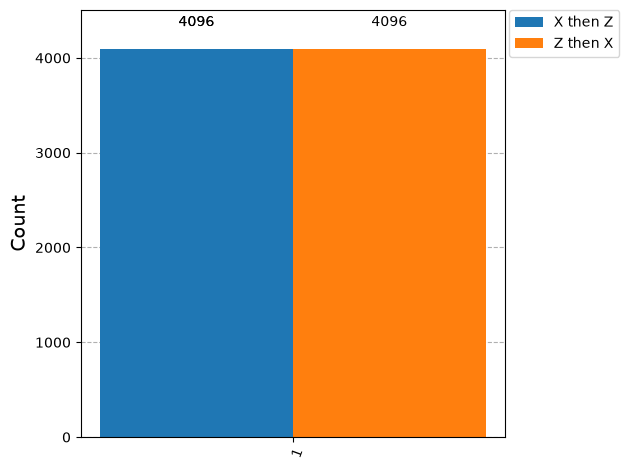

In [8]:
xz = QuantumCircuit(1); xz.x(0); xz.z(0)
zx = QuantumCircuit(1); zx.z(0); zx.x(0)
assert np.allclose(Operator(xz).data, -Operator(zx).data)
assert state(xz).equiv(state(zx))
print('X then Z:', state(xz).data, 'Z then X:', state(zx).data)
assert counts(xz) == counts(zx) == {'1': 4096}
display(plot_histogram([counts(xz), counts(zx)], legend=['X then Z', 'Z then X']))
assert Statevector.from_label('+').evolve(h).equiv(Statevector.from_label('0'))
assert Statevector.from_label('-').evolve(h).equiv(Statevector.from_label('1'))
plt.close('all')

### Exercise 5: Undo a Bell circuit

Undo gates in reverse order, replacing each with its inverse. H and CX are
self-inverse, so the manual inverse is CX then H. The result is |00>.

In [9]:
prep = bells['Phi+']
manual = prep.copy(); manual.cx(0, 1); manual.h(0)
automatic = prep.compose(prep.inverse())
for qc in [manual, automatic]:
    assert state(qc).equiv(Statevector.from_label('00'))
    assert Operator(qc).equiv(Operator(np.eye(4)))
print('Manual and automatic inverse both return |00>.')

Manual and automatic inverse both return |00>.


### Homework 1–3: Product states, GHZ, partial entanglement

Source: `week_4/homework.ipynb`, which already contains worked example cells.
Here the answers are checked and the GHZ circuit is generalized to n qubits.
For q0=|+>, q1=|−>, all four Z-basis outcomes have probability 1/4;
the joint distribution factorizes and concurrence is 0.
GHZ(n) = (|0…0> + |1…1>)/√2 has only two outcomes.
For cos(θ)|00> + sin(θ)|11>, concurrence is |sin(2θ)|;
θ=π/8 gives 1/√2, strictly between zero and one.

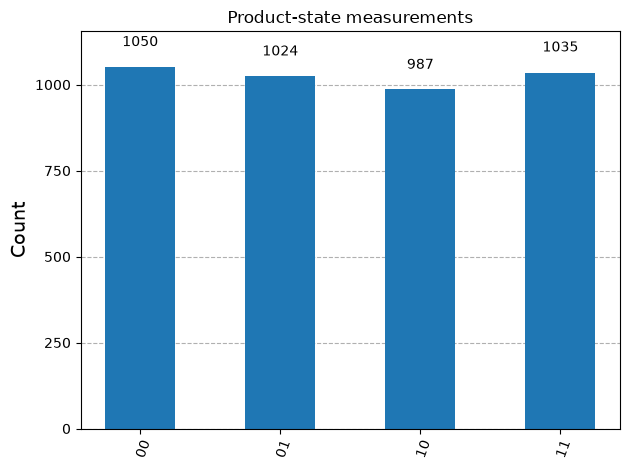

GHZ(2): {np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}
GHZ(3): {np.str_('000'): np.float64(0.4999999999999999), np.str_('111'): np.float64(0.4999999999999999)}
GHZ(5): {np.str_('00000'): np.float64(0.4999999999999999), np.str_('11111'): np.float64(0.4999999999999999)}
Partial concurrence: 0.7071067811865476


In [10]:
product = QuantumCircuit(2)
product.h(0); product.x(1); product.h(1)
sv = state(product)
assert np.allclose(sv.probabilities(), [0.25]*4)
assert np.allclose(sv.probabilities().reshape(2, 2), np.outer(sv.probabilities([1]), sv.probabilities([0])))
assert np.isclose(concurrence(sv), 0, atol=1e-7)
display(plot_histogram(counts(product), title='Product-state measurements'))

def ghz(n):
    if n < 2: raise ValueError('Use at least two qubits.')
    qc = QuantumCircuit(n); qc.h(0)
    for target in range(1, n): qc.cx(0, target)
    return qc

for n in [2, 3, 5]:
    expected_ghz = np.zeros(2**n); expected_ghz[[0, -1]] = 1 / np.sqrt(2)
    assert state(ghz(n)).equiv(expected_ghz)
    print(f'GHZ({n}):', state(ghz(n)).probabilities_dict())
theta = np.pi/8
partial = QuantumCircuit(2); partial.ry(2*theta, 0); partial.cx(0, 1)
assert state(partial).equiv([np.cos(theta), 0, 0, np.sin(theta)])
assert np.isclose(concurrence(state(partial)), 1/np.sqrt(2))
print('Partial concurrence:', concurrence(state(partial)))
plt.close('all')

## Week 5 — Transpilation

Source: `week_5/3-transpilation.ipynb`.
To keep this independent of cloud access and device snapshots, use a declared
native basis (RZ, SX, X, CX), matching the relevant Manila unitary gates, first
with unrestricted connectivity. Counts are specific to this basis/compiler.
Generic RZZ decomposes into CX–RZ–CX. Special angles can be cheaper:
RZZ(0)=I and RZZ(π)=−i Z⊗Z require no entangling gate after simplification.
Higher optimization need not improve every circuit or angle.

In [11]:
basis = ['rz', 'sx', 'x', 'cx']
print('theta/pi  level  gates  CX  depth')
for angle in [0, np.pi/3, np.pi/2, np.pi, 2*np.pi]:
    qc = QuantumCircuit(2); qc.rzz(angle, 0, 1)
    for level in range(4):
        compiled = transpile(qc, basis_gates=basis, optimization_level=level, seed_transpiler=SEED)
        assert Operator(qc).equiv(Operator(compiled))
        print(f'{angle/np.pi:8.3f} {level:6d} {compiled.size():6d} {compiled.count_ops().get("cx", 0):3d} {compiled.depth():6d}')

theta/pi  level  gates  CX  depth
   0.000      0      3   2      3
   0.000      1      0   0      0
   0.000      2      0   0      0
   0.000      3      0   0      0
   0.333      0      3   2      3
   0.333      1      3   2      3
   0.333      2      3   2      3
   0.333      3      3   2      3
   0.500      0      3   2      3
   0.500      1      3   2      3
   0.500      2     10   1      7
   0.500      3     10   1      7
   1.000      0      3   2      3
   1.000      1      3   2      3
   1.000      2      2   0      1
   1.000      3      2   0      1
   2.000      0      3   2      3
   2.000      1      0   0      0
   2.000      2      0   0      0
   2.000      3      0   0      0


### Combinations and routing cost

Compare the upstream five-qubit gate combination, a Toffoli, a SWAP, and a
four-qubit Pauli evolution. First isolate gate decomposition; then require a
five-qubit line with fixed initial layout, which may add routing SWAPs.
Operator.from_circuit accounts for the transpiler's final qubit permutation.

In [12]:
examples = {}
qc = QuantumCircuit(5); qc.ccx(0, 1, 2); examples['Toffoli'] = qc
qc = QuantumCircuit(5); qc.swap(0, 4); examples['distant SWAP'] = qc
qc = QuantumCircuit(5)
qc.append(PauliEvolutionGate(SparsePauliOp('ZZZX'), time=np.pi/3), [3, 2, 1, 0])
examples['Pauli evolution'] = qc
qc = QuantumCircuit(5)
qc.ccx(0, 1, 2); qc.swap(3, 4); qc.h(4); qc.sx(3); qc.cx(4, 0); qc.h(2); qc.ccx(2, 3, 4)
examples['combination'] = qc
line = [[a, b] for a, b in [(0,1), (1,0), (1,2), (2,1), (2,3), (3,2), (3,4), (4,3)]]
for name, qc in examples.items():
    for connectivity in [None, line]:
        compiled = transpile(qc, basis_gates=basis, coupling_map=connectivity,
                             initial_layout=list(range(5)), optimization_level=3, seed_transpiler=SEED)
        assert Operator(qc).equiv(Operator.from_circuit(compiled))
        print(name, 'all-to-all' if connectivity is None else 'line', dict(compiled.count_ops()), 'depth', compiled.depth())

Toffoli all-to-all {'rz': 10, 'cx': 6, 'sx': 2} depth 13
Toffoli line {'rz': 20, 'sx': 13, 'cx': 8} depth 28
distant SWAP all-to-all {} depth 0
distant SWAP line {} depth 0
Pauli evolution all-to-all {'cx': 6, 'rz': 5, 'sx': 2} depth 9
Pauli evolution line {'cx': 6, 'rz': 5, 'sx': 2} depth 9


combination all-to-all {'rz': 19, 'cx': 13, 'sx': 5} depth 26


combination line {'rz': 30, 'cx': 23, 'sx': 14} depth 46


/home/finn/Uni/test/cv/cleaningGitHub/Qiskit-fundamentals/.venv/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/finn/Uni/test/cv/cleaningGitHub/Qiskit-fundamentals/.venv/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


## Week 6 — V2 primitives

Source: `week_6/4-variational-QCs-and-primitives.ipynb`.
Use Qiskit's local [StatevectorSampler and StatevectorEstimator](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.3/primitives),
which implement the V2 interfaces.

### Exercise 1: RX parameter sweep in one PUB

P(1)=sin²(φ/2), maximized at π modulo 2π. The requested 20-point inclusive
grid does not contain π. Its two equal theoretical maxima are at 18π/19 and
20π/19. Shot noise can make either appear higher.

Sampled maximum at phi/pi = 0.9473684210526315


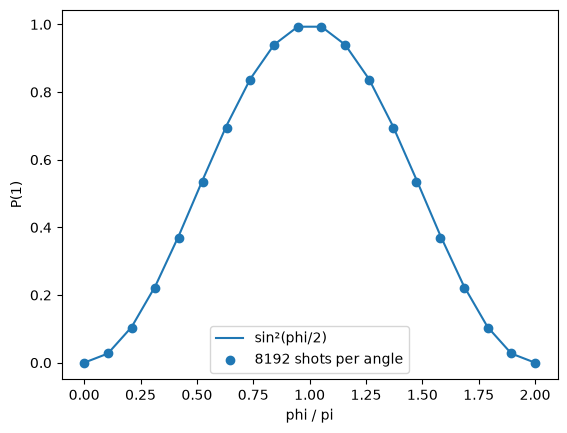

In [13]:
phi = Parameter('phi')
sweep = QuantumCircuit(1, 1); sweep.rx(phi, 0); sweep.measure(0, 0)
angles = np.linspace(0, 2*np.pi, 20)
shots = 8192
result = StatevectorSampler(seed=SEED).run([(sweep, angles[:, None], shots)]).result()[0]
probabilities = np.array([result.data.c.get_counts(i).get('1', 0)/shots for i in range(20)])
exact = np.sin(angles/2)**2
assert probabilities.shape == (20,)
assert np.max(np.abs(probabilities - exact)) < 0.03
for angle, probability in zip(angles, exact):
    qc = QuantumCircuit(1); qc.rx(angle, 0)
    assert np.isclose(state(qc).probabilities()[1], probability)
print('Sampled maximum at phi/pi =', angles[np.argmax(probabilities)]/np.pi)
plt.plot(angles/np.pi, exact, label='sin²(phi/2)')
plt.scatter(angles/np.pi, probabilities, label='8192 shots per angle')
plt.xlabel('phi / pi'); plt.ylabel('P(1)'); plt.legend(); plt.show()
plt.close('all')

### Exercise 2: Bell correlations in one Estimator call

ZZ gives +1 for 00 and 11, so Φ+ always has even Z parity, even though each
individual measurement is random. XX also gives +1 for Φ+.
The four Bell states have (ZZ,XX) values (+1,+1), (+1,−1), (−1,+1), (−1,−1).
These two correlations distinguish their relative signs as well as their parity.

In [14]:
observables = [SparsePauliOp('ZZ'), SparsePauliOp('XX')]
results = StatevectorEstimator().run([(qc, observables) for qc in bells.values()]).result()
expected_correlations = [[1, 1], [1, -1], [-1, 1], [-1, -1]]
for (name, qc), result, expected_values in zip(bells.items(), results, expected_correlations):
    assert np.allclose(result.data.evs, expected_values)
    print(name, '(ZZ, XX) =', result.data.evs)

Phi+ (ZZ, XX) = [1. 1.]
Phi- (ZZ, XX) = [ 1. -1.]
Psi+ (ZZ, XX) = [-1.  1.]
Psi- (ZZ, XX) = [-1. -1.]


## Week 7 — Rotation axis and hopping Hamiltonian

Source: `week_7/5-VQE-part-1.ipynb` (embedded questions).
RX(π) or RY(π) prepares |1> from |0> up to global phase; RZ cannot change
the populations of |0> and |1>.
The Hamiltonian H=(XX+YY)/2 exchanges |01> and |10> and annihilates |00>,|11>.
H itself is not a unitary gate. Its time evolution exp(−itH) swaps the
single-excitation states at t=π/2 with a factor −i and leaves |00>,|11> unchanged.

In [15]:
for axis in ['rx', 'ry', 'rz']:
    qc = QuantumCircuit(1); getattr(qc, axis)(np.pi, 0)
    assert state(qc).equiv(Statevector.from_label('0' if axis == 'rz' else '1'))
    print(axis, state(qc).data)
hamiltonian = SparsePauliOp(['XX', 'YY'], coeffs=[0.5, 0.5])
matrix = hamiltonian.to_matrix()
assert np.allclose(matrix @ Statevector.from_label('01').data, Statevector.from_label('10').data)
assert np.allclose(matrix @ Statevector.from_label('10').data, Statevector.from_label('01').data)
evolution = QuantumCircuit(2)
evolution.append(PauliEvolutionGate(hamiltonian, time=np.pi/2), [0, 1])
for start, end in [('01', '10'), ('10', '01')]:
    assert np.allclose(Statevector.from_label(start).evolve(evolution).data, -1j*Statevector.from_label(end).data)
for label in ['00', '11']:
    assert np.allclose(matrix @ Statevector.from_label(label).data, np.zeros(4))
    assert np.allclose(Statevector.from_label(label).evolve(evolution).data, Statevector.from_label(label).data)
print('All exercise checks passed.')

rx [6.123234e-17+0.j 0.000000e+00-1.j]
ry [6.123234e-17+0.j 1.000000e+00+0.j]
rz [6.123234e-17-1.j 0.000000e+00+0.j]
All exercise checks passed.
